# Live Example  Notes

Companion notebook for the live-examples notebook `sample.ipynb`.
Sections follow the exact order of the original cells.

**Contents**

1. Setting up the environment
2. Creating data manually — `pandas.Series`
3. Loading real data
4. Data cleaning — fixing data types
5. Summary statistics for mixed data
6. Univariate analysis of a categorical column
7. Splitting columns by data type
8. Built-in datasets (`tips`)
9. Handling missing values
10. Mean vs. median — why outliers matter
11. Visualising outliers
12. Detecting outliers with the IQR rule
13. Duplicates
14. Looping over columns — automating EDA
15. The EDA workflow checklist
16. Common mistakes
17. Exercises

---
## 1. Setting Up the Environment

| Library | Purpose |
|---|---|
| `pandas` | Tabular data handling (Series, DataFrame) |
| `seaborn` | Statistical plots, built on matplotlib |
| `matplotlib.pyplot` | Base plotting engine / figure control |

**Teaching points**

- `%matplotlib inline` is a *magic command* — it renders plots inside the notebook instead of a pop-up window.
- Install with `!pip install seaborn` (bang) inside a notebook cell; `%pip install seaborn` is the modern, kernel-safe form.
- Import aliases (`pd`, `sns`, `plt`) are community conventions — always follow them.

In [ ]:
%pip install seaborn

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

---
## 2. Creating Data Manually — `pandas.Series`

**Concept: Series**

- A `Series` is a **1-dimensional labelled array** — think of it as a single column of a table.
- It has two parts: the **index** (labels) and the **values**.

**Teaching points**

- `random.randint(45, 100)` is **inclusive** on both ends.
- `range(1, 200)` produces 199 items — not 200. Great place to discuss off-by-one errors.
- Default index is `RangeIndex` starting from 0.

In [ ]:
import random

marks = [random.randint(45, 100) for i in range(1, 200)]

len(marks), marks[:10]

In [ ]:
ser = pd.Series(data=marks)
ser.head()

### 2.1 `describe()` — the five-number summary

| Statistic | Meaning |
|---|---|
| `count` | Number of non-null values |
| `mean` | Arithmetic average |
| `std` | Standard deviation (spread around the mean) |
| `min` | Smallest value |
| `25%` (Q1) | 25% of data lies below this |
| `50%` (Q2) | Median |
| `75%` (Q3) | 75% of data lies below this |
| `max` | Largest value |

**Expected result here:** since the data is *uniformly* random between 45–100, mean ≈ median ≈ 72.5.
This is a nice demonstration of a **symmetric distribution**.

In [ ]:
ser.describe()

### 2.2 Quick plot

- Default `kind='line'` → index on X-axis, value on Y-axis.
- For random data this looks like noise — a good teaching moment: **a line plot is meaningless without a meaningful ordering (e.g., time).**
- Better choice here: `ser.plot(kind='hist')` or `sns.histplot(ser)`.

In [ ]:
ser.plot()
plt.show()

sns.histplot(ser, kde=True)
plt.title("Better choice: histogram of marks")
plt.show()

---
## 3. Loading Real Data

**Teaching points**

- The `r""` prefix creates a **raw string** so Windows backslashes are not read as escape characters (`\n`, `\t`).
- Alternatives: forward slashes `"D:/data/file.csv"` or double backslashes.
- Prefer **relative paths** in shared projects so notebooks run on any machine.
- Other readers: `read_excel`, `read_json`, `read_sql`, `read_parquet`.

In [2]:
subcribers_df = pd.read_csv(r"D:\Data Science_bat\Pandas_topic\subscribers.csv")
subcribers_df.head()

,Unnamed: 0,user_id,age_group,city_tier,subscription_date,subscription_plan,last_active_date,plan_change_date,new_subscription_plan
0,0,UIDJS0000751588f,18-24,Tier 1,2024-06-10,Premium,NaN,NaN,NaN
1,1,UIDJS000093eeb86,18-24,Tier 1,2024-11-09,Free,NaN,NaN,NaN
2,2,UIDJS00010d7fa1e,25-34,Tier 1,2024-08-08,Free,NaN,NaN,NaN
3,3,UIDJS00013411a85,35-44,Tier 2,2024-05-31,VIP,NaN,NaN,NaN
4,4,UIDJS0003a3f54cf,35-44,Tier 1,2024-09-20,Premium,NaN,NaN,NaN


### 3.1 First look at a DataFrame

In [4]:
print(subcribers_df.shape)      # (rows, columns)
print(subcribers_df.columns)    # column names
subcribers_df.tail()            # last 5 rows

(44620, 9)
Index(['Unnamed: 0', 'user_id', 'age_group', 'city_tier', 'subscription_date',
       'subscription_plan', 'last_active_date', 'plan_change_date',
       'new_subscription_plan'],
      dtype='object')


,Unnamed: 0,user_id,age_group,city_tier,subscription_date,subscription_plan,last_active_date,plan_change_date,new_subscription_plan
44615,44615,UIDJSfffbb38249e,25-34,Tier 2,2024-11-12,Free,NaN,NaN,NaN
44616,44616,UIDJSfffbd759005,45+,Tier 1,2024-05-21,VIP,NaN,NaN,NaN
44617,44617,UIDJSfffebd3002b,25-34,Tier 1,2024-09-27,VIP,2024-10-29,NaN,NaN
44618,44618,UIDJSffff6698084,35-44,Tier 3,2024-10-12,VIP,NaN,NaN,NaN
44619,44619,UIDJSffffe298c56,25-34,Tier 2,2024-09-10,Free,NaN,NaN,NaN


### 3.2 `info()` — structure & data types

Tells you:

1. Number of rows (`RangeIndex`)
2. Column names
3. **Non-null count** → instantly reveals missing data
4. **Dtype** of each column
5. Memory usage

**Key idea:** dates loaded from CSV arrive as `object` (string). They must be converted before any date arithmetic.

In [5]:
subcribers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44620 entries, 0 to 44619
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Unnamed: 0             44620 non-null  int64 
 1   user_id                44620 non-null  object
 2   age_group              44620 non-null  object
 3   city_tier              44620 non-null  object
 4   subscription_date      44620 non-null  object
 5   subscription_plan      44620 non-null  object
 6   last_active_date       6652 non-null   object
 7   plan_change_date       7090 non-null   object
 8   new_subscription_plan  7090 non-null   object
dtypes: int64(1), object(8)
memory usage: 3.1+ MB


---
## 4. Data Cleaning — Fixing Data Types

**Why convert?** Only after conversion can you:

- Subtract dates → `Timedelta` (e.g., subscription tenure)
- Use the `.dt` accessor: `.dt.year`, `.dt.month`, `.dt.day_name()`
- Resample / group by time period
- Sort chronologically instead of alphabetically

The original notebook used `.astype("datetime64[ns]")`. A **more robust alternative** uses
`pd.to_datetime(..., errors="coerce")`, which turns unparseable values into `NaT`
instead of raising an error. You can also parse at load time with
`pd.read_csv(path, parse_dates=date_cols)`.

Always re-run `.info()` after conversion to **verify** the change.

In [3]:
date_cols = ["subscription_date", "plan_change_date", "last_active_date"]

for col in date_cols:
    subcribers_df[col] = pd.to_datetime(subcribers_df[col], errors="coerce")

subcribers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44620 entries, 0 to 44619
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             44620 non-null  int64         
 1   user_id                44620 non-null  object        
 2   age_group              44620 non-null  object        
 3   city_tier              44620 non-null  object        
 4   subscription_date      44620 non-null  datetime64[ns]
 5   subscription_plan      44620 non-null  object        
 6   last_active_date       6652 non-null   datetime64[ns]
 7   plan_change_date       7090 non-null   datetime64[ns]
 8   new_subscription_plan  7090 non-null   object        
dtypes: datetime64[ns](3), int64(1), object(5)
memory usage: 3.1+ MB


---
## 5. Summary Statistics for Mixed Data

| Argument | Behaviour |
|---|---|
| default | Numeric columns only |
| `include="all"` | All columns; irrelevant stats become `NaN` |
| `include="object"` | Text/categorical only |
| `include=["int64","float64"]` | Specific dtypes |

**Extra stats shown for categorical columns**

- `unique` — number of distinct values
- `top` — most frequent value (mode)
- `freq` — how many times `top` appears

In [ ]:
subcribers_df.describe(include="all")

---
## 6. Univariate Analysis of a Categorical Column

**Chain explained**

1. `['subscription_plan']` → select one column (a Series)
2. `.value_counts()` → frequency of each category, sorted descending
3. `.plot(kind="barh")` → horizontal bar chart

**Teaching points**

- `value_counts(normalize=True)` gives proportions/percentages.
- `value_counts(dropna=False)` includes `NaN` in the counts — very useful for auditing missing data.
- Use **horizontal** bars when category names are long.
- Bar charts are for *categorical* data; histograms are for *continuous* data.

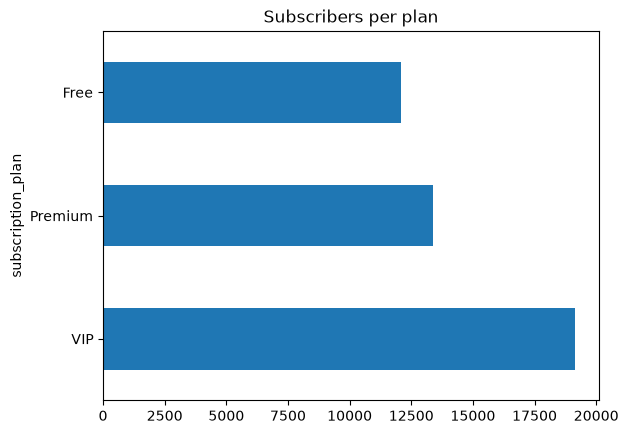

subscription_plan
VIP        42.933662
Premium    29.957418
Free       27.108920
Name: proportion, dtype: float64

In [5]:
subcribers_df["subscription_plan"].value_counts().plot(kind="barh")
plt.title("Subscribers per plan")
plt.show()

subcribers_df["subscription_plan"].value_counts(normalize=True) * 100

---
## 7. Splitting Columns by Data Type

**Why split?** EDA techniques differ by type:

| Type | Summary | Plots |
|---|---|---|
| Numerical | `describe()`, mean, median, std | histogram, boxplot, KDE, scatter |
| Categorical | `value_counts()`, mode | countplot, bar chart, pie |

For the insurance dataset:

- Numerical → `age`, `bmi`, `children`, `charges`
- Categorical → `sex`, `smoker`, `region`

> **Caution:** `children` is stored as an integer but is really **discrete/ordinal**.
> Statistics like its "mean" are less meaningful. Discuss *storage type vs. semantic type*.

In [ ]:
insurance_df = pd.read_csv(r"D:\Data Science_bat\Machine Learning\Raw_datasets\insurance.csv")
insurance_df.info()

In [ ]:
# dtype-agnostic and safer than listing int64/float64 explicitly
ins_num_df = insurance_df.select_dtypes(include="number")
ins_cat_df = insurance_df.select_dtypes(include=["object", "category"])

print(ins_num_df.columns.tolist())
print(ins_cat_df.columns.tolist())

---
## 8. Built-in Datasets (`tips`)

- Seaborn ships small practice datasets: `tips`, `titanic`, `iris`, `penguins`, `flights`, `diamonds`.
- In `tips`, the text columns are already dtype **`category`**, not `object`.

**Important teaching moment:** in the original notebook, `numerical_df` / `categorical_df` were
**overwritten** here with tips data. This is a classic notebook pitfall — later cells that assume
they hold insurance data silently give wrong results.

> **Rule for students:** use descriptive, dataset-prefixed names — `ins_num_df`, `tips_cat_df` —
> and remember that notebook state depends on *execution order*, not cell order.

**Why `category` dtype matters**

- Uses far less memory than `object`
- Can carry an explicit order (`Ordered Categorical`)
- Some libraries treat it specially

In [7]:
tips_df = sns.load_dataset("tips")
tips_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [ ]:
tips_num_df = tips_df.select_dtypes(include="number")
tips_cat_df = tips_df.select_dtypes(include="category")

tips_cat_df.head()

---
## 9. Handling Missing Values

**Chain explained**

- `isnull()` → DataFrame of `True`/`False`
- `.sum()` → column-wise count (True counts as 1)

In [ ]:
print(insurance_df.isnull().sum())            # missing per column
print(insurance_df.isnull().sum().sum())      # total missing cells
print(insurance_df.isnull().mean() * 100)     # % missing per column

sns.heatmap(insurance_df.isnull(), cbar=False)
plt.title("Missing-value map")
plt.show()

### 9.1 Imputation

The original notebook wrote:

```python
avg_age = insurance_df['age'].mean()
insurance_df.fillna(avg_age)
```

**Two bugs to discuss with students:**

1. **Not saved.** `fillna()` returns a *new* DataFrame. Without assignment (or `inplace=True`), the original is unchanged.
2. **Wrong scope.** This fills *every* column with the mean **age** — filling `charges` or `bmi` with an age value is nonsense.

**Choosing a strategy**

| Situation | Strategy |
|---|---|
| Numeric, roughly symmetric | Mean |
| Numeric, skewed or has outliers | **Median** (safer default) |
| Categorical | Mode / a new `"Unknown"` category |
| Time series | Forward fill `ffill()` / interpolation |
| Very high % missing | Consider dropping the column |
| Few missing rows | `dropna()` |

In [ ]:
# correct approach: impute per column, with a strategy suited to that column
for col in ins_num_df.columns:
    insurance_df[col] = insurance_df[col].fillna(insurance_df[col].median())

for col in ins_cat_df.columns:
    insurance_df[col] = insurance_df[col].fillna(insurance_df[col].mode()[0])

insurance_df.isnull().sum()

---
## 10. Mean vs. Median — Why Outliers Matter

**Core lesson**

- The **mean is sensitive** to extreme values; the **median is robust**.
- `120` is clearly a **data-entry error** (unit mix-up: cm vs. ft).
- Rule of thumb: if mean $\gg$ median, the data is **right-skewed** / has high outliers.
- This is why we prefer the **median** for imputation and for reporting skewed values like income or medical charges.

In [ ]:
heights = [5, 6, 4.5, 4.7, 5, 7, 120]

h_sr = pd.Series(heights)

print("plain average :", sum(heights) / len(heights))
print("mean          :", h_sr.mean())    # dragged up by 120
print("median        :", h_sr.median())  # unaffected

---
## 11. Visualising Outliers

### Reading a boxplot

```text
    |-----[   |   ]-----|    o   o    o
   min    Q1  Q2   Q3  max          outliers
 (whisker)        (whisker)
```

- **Box** = IQR, spans Q1 → Q3, containing the middle 50% of data
- **Line inside box** = median
- **Whiskers** = extend to the furthest point within 1.5 × IQR
- **Dots beyond whiskers** = candidate outliers

### `boxplot` vs `boxenplot`

| Plot | Best for | Detail |
|---|---|---|
| `boxplot` | General use, small/medium data | Shows quartiles only |
| `boxenplot` (letter-value plot) | Large datasets | Shows many more quantile levels → better view of tail shape |

**Interpretation for `charges`:** the distribution is strongly **right-skewed** — most people have
low medical costs, a small group (likely smokers / chronic conditions) has very high costs.

In [ ]:
# modern seaborn syntax: pass data= and x= instead of a bare Series
sns.boxplot(data=insurance_df, x="charges")
plt.title("boxplot of charges")
plt.show()

sns.boxenplot(data=insurance_df, x="charges")
plt.title("boxenplot of charges")
plt.show()

---
## 12. Detecting Outliers with the IQR Rule

$$IQR = Q3 - Q1$$
$$\text{Lower fence} = Q1 - 1.5 \times IQR$$
$$\text{Upper fence} = Q3 + 1.5 \times IQR$$

**Teaching points**

- `describe()` returns a Series, so quartiles can be pulled out by label: `charges_info['25%']`.
- Equivalent direct method: `insurance_df['charges'].quantile(0.25)`.
- Why 1.5? It is a convention (Tukey) that flags roughly the most extreme ~0.7% of a normal distribution. Use **3.0** for "extreme" outliers only.
- For `charges`, the lower fence comes out **negative** — impossible for a cost. So *no* low outliers exist; all outliers are on the high side.

In [ ]:
charges_info = insurance_df["charges"].describe()

Q1 = charges_info["25%"]
Q3 = charges_info["75%"]
IQR = Q3 - Q1

lower_boundry = Q1 - (1.5 * IQR)
upper_boundry = Q3 + (1.5 * IQR)

print(f"Q1={Q1:.2f}  Q3={Q3:.2f}  IQR={IQR:.2f}")
print(f"fences: {lower_boundry:.2f} .. {upper_boundry:.2f}")

### 12.1 Filtering out the outliers

**Boolean masking explained**

1. Each comparison produces a `True`/`False` Series.
2. `&` combines them element-wise (**must** use `&`, not `and`).
3. **Parentheses are mandatory** — `&` binds tighter than `<`.
4. `df[mask]` keeps only the `True` rows.

> **Should you always remove outliers?** No. In this dataset, high charges are *genuine*
> high-cost patients, not errors — removing them may destroy the very signal you want to model.
> Remove outliers when they are **errors**; investigate them when they are **real**.

In [ ]:
mask = insurance_df["charges"].between(lower_boundry, upper_boundry)

# .copy() avoids SettingWithCopyWarning on later in-place edits
outlier_removed_df = insurance_df[mask].copy()

print(insurance_df.shape, "->", outlier_removed_df.shape)

---
## 13. Duplicates

**Teaching points**

- `duplicated()` marks a row `True` if an *identical* row appeared earlier.
- `keep='first'` (default) / `'last'` / `False` (mark all copies).
- `subset=['col1','col2']` checks duplicates on selected columns only (e.g., duplicate customer IDs).
- `.shape` afterwards confirms how many rows were dropped — **always verify a cleaning step**.

> **`SettingWithCopyWarning`.** In the original notebook `outlier_removed_df` was created by slicing,
> so it may be a *view*. Calling `drop_duplicates(inplace=True)` on it triggers a warning and may not
> work reliably. Fix by adding `.copy()` when slicing (done above) or by reassigning.

In [ ]:
print("duplicates:", outlier_removed_df.duplicated().sum())

outlier_removed_df = outlier_removed_df.drop_duplicates()

outlier_removed_df.shape

---
## 14. Looping Over Columns — Automating EDA

### 14.1 Frequency of every categorical column

- Iterating a DataFrame directly yields **column names**.
- More explicit and readable: `for col in df.columns:`

In [ ]:
for col in ins_cat_df.columns:
    print(f"--- {col} ---")
    print(insurance_df[col].value_counts())
    print()

### 14.2 Count plots for all categorical columns

- `sns.countplot` = bar chart of `value_counts()`.
- `plt.show()` **inside** the loop is essential — without it, all plots draw on one figure.

In [ ]:
for col in ins_cat_df.columns:
    sns.countplot(data=insurance_df, x=col)
    plt.title(f"Distribution of {col}")
    plt.show()

### 14.3 Distribution + outlier scan for all numerical columns

Purpose: scan **every** numeric feature for outliers and skew in one pass.

In [ ]:
for col in ins_num_df.columns:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(insurance_df[col], kde=True, ax=ax[0])
    sns.boxplot(x=insurance_df[col], ax=ax[1])
    fig.suptitle(col)
    plt.show()

---
## 15. The EDA Workflow — Summary Checklist

| # | Step | Key commands |
|---|---|---|
| 1 | Load data | `pd.read_csv()` |
| 2 | Inspect shape & structure | `.head()`, `.shape`, `.info()` |
| 3 | Fix data types | `.astype()`, `pd.to_datetime()` |
| 4 | Summary statistics | `.describe(include="all")` |
| 5 | Split by type | `.select_dtypes()` |
| 6 | Check missing values | `.isnull().sum()` |
| 7 | Impute / drop | `.fillna()`, `.dropna()` |
| 8 | Check duplicates | `.duplicated().sum()`, `.drop_duplicates()` |
| 9 | Univariate — categorical | `.value_counts()`, `sns.countplot()` |
| 10 | Univariate — numerical | `sns.histplot()`, `sns.boxplot()` |
| 11 | Outlier detection | IQR rule + boolean masking |
| 12 | Bivariate analysis | `sns.scatterplot()`, `sns.barplot()`, `.corr()` |

In [ ]:
# step 12 preview: bivariate analysis
sns.heatmap(insurance_df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

sns.scatterplot(data=insurance_df, x="age", y="charges", hue="smoker")
plt.title("Charges vs age, split by smoker")
plt.show()

---
## 17. Suggested Exercises

1. Compute the average subscription tenure in days from `subscription_date` and `last_active_date`.
2. Compare mean vs. median `charges` for smokers and non-smokers — which differs more, and why?
3. Write a reusable function `iqr_outliers(df, col)` returning the fences and the outlier rows.
4. Build a correlation heatmap of `insurance_df` numeric columns.
5. Create a `sns.pairplot(insurance_df, hue='smoker')` and describe three insights.
6. Rewrite the missing-value handling so each column uses an appropriate strategy.

In [ ]:
# exercise scratch space

In [7]:
subcribers_df['age_group'].value_counts()

age_group
25-34    20069
35-44    11274
18-24     7676
45+       5601
Name: count, dtype: int64

# Example for univariate analysis

<Axes: xlabel='age_group', ylabel='count'>

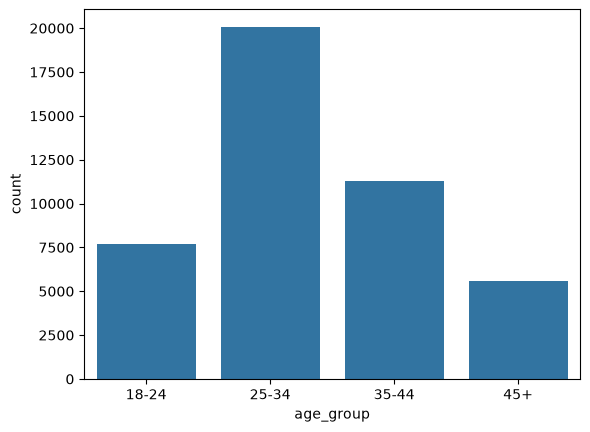

In [4]:
sns.countplot(data= subcribers_df, x = 'age_group')

# Example for bivariate analysis

In [5]:
subcribers_df.columns

Index(['Unnamed: 0', 'user_id', 'age_group', 'city_tier', 'subscription_date',
       'subscription_plan', 'last_active_date', 'plan_change_date',
       'new_subscription_plan'],
      dtype='object')

<Axes: xlabel='age_group', ylabel='count'>

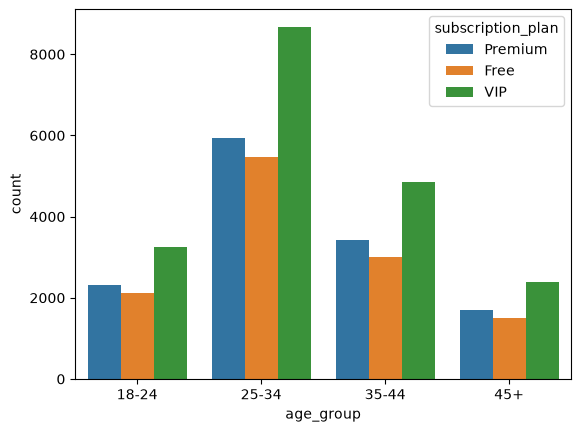

In [6]:
sns.countplot(data= subcribers_df, x = 'age_group', hue="subscription_plan")


In [9]:
tips_df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

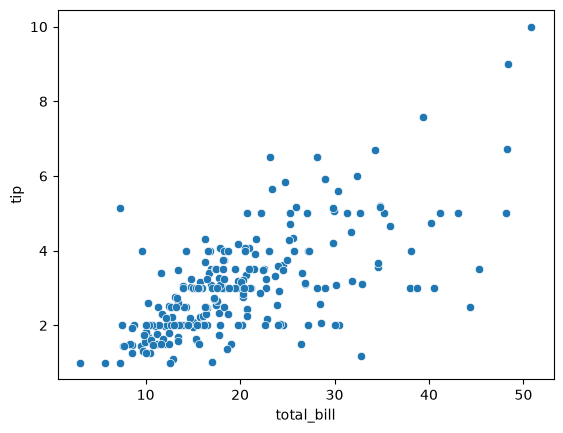

In [ ]:
# tips_df.select_dtypes(include=["int", "float"])
x`x```

sns.scatterplot(data= tips_df, x= 'total_bill', y='tip')

In [ ]:
tips_df[['total_bill','tip']].corr()

,total_bill,tip
total_bill,1.000000,0.675734
tip,0.675734,1.000000


In [14]:
tips_df.select_dtypes(include=["int", "float"]).corr()


,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


<Axes: >

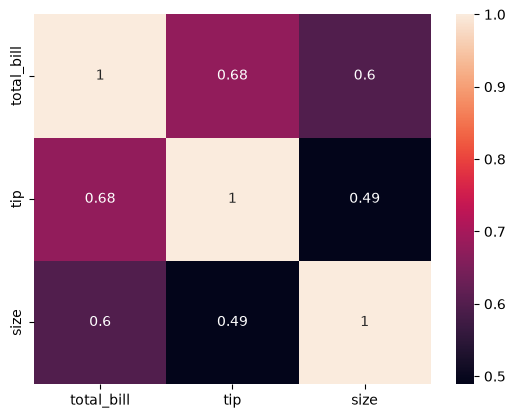

In [16]:
sns.heatmap(tips_df.select_dtypes(include=["int", "float"]).corr(), annot= True)

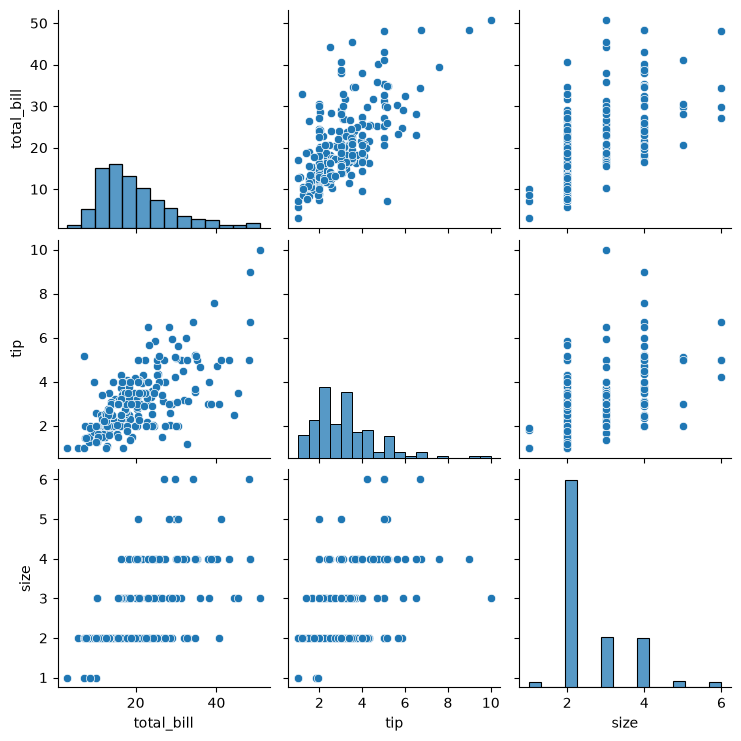

In [17]:
sns.pairplot(tips_df.select_dtypes(include=["int", "float"]))